## ELECTRICITY GRID TIME SERIES DATA EXPLORATORY DATA ANALYSIS

- step 1: open and save as parquet file for easier handling 
- step 2: merge the files frmo 2018-23
- step 3: start EDA univariate and multivariate

In [ ]:
import numpy as np 
import pyarrow.parquet as pq
import pyarrow.csv as pv
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import math 


In [7]:
df_18 = df = pd.read_csv("../data/raw/demanddata_2018.csv")
df_19 = df = pd.read_csv("../data/raw/demanddata_2019.csv")
df_20 = df = pd.read_csv("../data/raw/demanddata_2020.csv")
df_21 = df = pd.read_csv("../data/raw/demanddata_2021.csv")
df_22 = df = pd.read_csv("../data/raw/demanddata_2022.csv")
df_23 = df = pd.read_csv("../data/raw/demanddata_2023.csv")

- Convert to parquet and save

In [43]:
df_18.to_parquet("../data/demanddata_2018.parquet", engine="pyarrow", index=False)
df_19.to_parquet("../data/demanddata_2019.parquet", engine="pyarrow", index=False)
df_20.to_parquet("../data/demanddata_2020.parquet", engine="pyarrow", index=False)
df_21.to_parquet("../data/demanddata_2021.parquet", engine="pyarrow", index=False)
df_22.to_parquet("../data/demanddata_2022.parquet", engine="pyarrow", index=False)
df_23.to_parquet("../data/demanddata_2023.parquet", engine="pyarrow", index=False)

- open and observe parquet files

In [44]:
df_18 = pd.read_parquet("../data/demanddata_2018.parquet", engine="pyarrow")
df_19 = pd.read_parquet("../data/demanddata_2019.parquet", engine="pyarrow")
df_20 = pd.read_parquet("../data/demanddata_2020.parquet", engine="pyarrow")
df_21 = pd.read_parquet("../data/demanddata_2021.parquet", engine="pyarrow")
df_22 = pd.read_parquet("../data/demanddata_2022.parquet", engine="pyarrow")
df_23 = pd.read_parquet("../data/demanddata_2023.parquet", engine="pyarrow")


In [45]:
# check if columns of datasets are the same so that they are prepped for merge:
dfs = [df_18, df_19, df_20, df_21, df_22, df_23]
labels = [f"Dataset {i}" for i in range(18, 24)]

# 2. Compute the comparison matrix
# Change '.equals()' to 'set(a.columns) == set(b.columns)' if column order does not matter
matrix_data = [
    [int(a.columns.equals(b.columns)) for b in dfs] for a in dfs
]

# 3. Format as a clean DataFrame
matrix_df = pd.DataFrame(matrix_data, index=labels, columns=labels)
print(matrix_df)

# matrix 19-22 all match up, datasets 18 and 23 have different columns 

            Dataset 18  Dataset 19  Dataset 20  Dataset 21  Dataset 22  \
Dataset 18           1           0           0           0           0   
Dataset 19           0           1           1           1           1   
Dataset 20           0           1           1           1           1   
Dataset 21           0           1           1           1           1   
Dataset 22           0           1           1           1           1   
Dataset 23           0           0           0           0           0   

            Dataset 23  
Dataset 18           0  
Dataset 19           0  
Dataset 20           0  
Dataset 21           0  
Dataset 22           0  
Dataset 23           1  


In [ ]:
df_18.columns.equals(df_23.columns)
df_18.columns
df_23.columns
# dataset 18 - does not contain: any flow columns, dataset 23 does

Index(['SETTLEMENT_DATE', 'SETTLEMENT_PERIOD', 'ND', 'TSD',
       'ENGLAND_WALES_DEMAND', 'EMBEDDED_WIND_GENERATION',
       'EMBEDDED_WIND_CAPACITY', 'EMBEDDED_SOLAR_GENERATION',
       'EMBEDDED_SOLAR_CAPACITY', 'NON_BM_STOR', 'PUMP_STORAGE_PUMPING',
       'SCOTTISH_TRANSFER', 'IFA_FLOW', 'IFA2_FLOW', 'BRITNED_FLOW',
       'MOYLE_FLOW', 'EAST_WEST_FLOW', 'NEMO_FLOW', 'NSL_FLOW',
       'ELECLINK_FLOW', 'VIKING_FLOW', 'GREENLINK_FLOW'],
      dtype='str')

In [46]:
print(df_19.columns) # no scottish transfer flow in df 19-22
print(df_23.columns)
print(df_18.columns) # 'NSL_FLOW','ELECLINK_FLOW', 'VIKING_FLOW', 'GREENLINK_FLOW' or SCOTTISH TRANSFER

Index(['SETTLEMENT_DATE', 'SETTLEMENT_PERIOD', 'ND', 'TSD',
       'ENGLAND_WALES_DEMAND', 'EMBEDDED_WIND_GENERATION',
       'EMBEDDED_WIND_CAPACITY', 'EMBEDDED_SOLAR_GENERATION',
       'EMBEDDED_SOLAR_CAPACITY', 'NON_BM_STOR', 'PUMP_STORAGE_PUMPING',
       'IFA_FLOW', 'IFA2_FLOW', 'BRITNED_FLOW', 'MOYLE_FLOW', 'EAST_WEST_FLOW',
       'NEMO_FLOW', 'NSL_FLOW', 'ELECLINK_FLOW', 'VIKING_FLOW',
       'GREENLINK_FLOW', 'SCOTTISH_TRANSFER'],
      dtype='str')
Index(['SETTLEMENT_DATE', 'SETTLEMENT_PERIOD', 'ND', 'TSD',
       'ENGLAND_WALES_DEMAND', 'EMBEDDED_WIND_GENERATION',
       'EMBEDDED_WIND_CAPACITY', 'EMBEDDED_SOLAR_GENERATION',
       'EMBEDDED_SOLAR_CAPACITY', 'NON_BM_STOR', 'PUMP_STORAGE_PUMPING',
       'SCOTTISH_TRANSFER', 'IFA_FLOW', 'IFA2_FLOW', 'BRITNED_FLOW',
       'MOYLE_FLOW', 'EAST_WEST_FLOW', 'NEMO_FLOW', 'NSL_FLOW',
       'ELECLINK_FLOW', 'VIKING_FLOW', 'GREENLINK_FLOW'],
      dtype='str')
Index(['SETTLEMENT_DATE', 'SETTLEMENT_PERIOD', 'ND', 'TSD',
       'ENGL

- Create extra blank columns in other dataset so that merge shape of dfs is same
- Ensure all columns in other datasets follow same order of columns as is df_23
- emsure the source columns is included

In [47]:
dfs_dict = {
    'df_18': df_18, 
    'df_19': df_19, 
    'df_20': df_20, 
    'df_21': df_21, 
    'df_22': df_22, 
    'df_23': df_23
}
missing_cols = ['SCOTTISH_TRANSFER', 'NSL_FLOW', 'ELECLINK_FLOW', 'VIKING_FLOW', 'GREENLINK_FLOW']
target_order = list(df_23.columns) + ['df_source'] if 'df_source' not in df_23.columns else list(df_23.columns)

# Loop through the dictionary to handle missing columns, source tagging, and alignment
for name, df in dfs_dict.items():
    # 1. Fill missing columns with NaN
    for col in missing_cols:
        if col not in df.columns:
            df[col] = np.nan
            
    # 2. Correctly tag the source as a string literal
    df['df_source'] = name
    
    # 3. Enforce the df_23 column order across all DataFrames
    dfs_dict[name] = df.reindex(columns=target_order)

# extract back to orignal variables from dictionary values 
df_18, df_19, df_20, df_21, df_22, df_23 = dfs_dict.values()


In [50]:
target_order = list(df_23.columns)

for i in dfs:
    i = i.reindex(columns = target_order)

In [51]:
for i in dfs:
    print(i.columns)

Index(['SETTLEMENT_DATE', 'SETTLEMENT_PERIOD', 'ND', 'TSD',
       'ENGLAND_WALES_DEMAND', 'EMBEDDED_WIND_GENERATION',
       'EMBEDDED_WIND_CAPACITY', 'EMBEDDED_SOLAR_GENERATION',
       'EMBEDDED_SOLAR_CAPACITY', 'NON_BM_STOR', 'PUMP_STORAGE_PUMPING',
       'IFA_FLOW', 'IFA2_FLOW', 'BRITNED_FLOW', 'MOYLE_FLOW', 'EAST_WEST_FLOW',
       'NEMO_FLOW', 'SCOTTISH_TRANSFER', 'NSL_FLOW', 'ELECLINK_FLOW',
       'VIKING_FLOW', 'GREENLINK_FLOW', 'df_source'],
      dtype='str')
Index(['SETTLEMENT_DATE', 'SETTLEMENT_PERIOD', 'ND', 'TSD',
       'ENGLAND_WALES_DEMAND', 'EMBEDDED_WIND_GENERATION',
       'EMBEDDED_WIND_CAPACITY', 'EMBEDDED_SOLAR_GENERATION',
       'EMBEDDED_SOLAR_CAPACITY', 'NON_BM_STOR', 'PUMP_STORAGE_PUMPING',
       'IFA_FLOW', 'IFA2_FLOW', 'BRITNED_FLOW', 'MOYLE_FLOW', 'EAST_WEST_FLOW',
       'NEMO_FLOW', 'NSL_FLOW', 'ELECLINK_FLOW', 'VIKING_FLOW',
       'GREENLINK_FLOW', 'SCOTTISH_TRANSFER', 'df_source'],
      dtype='str')
Index(['SETTLEMENT_DATE', 'SETTLEMENT_PERIOD',

In [56]:
df_merged = pd.concat([df_18, df_19, df_20, df_21, df_22, df_23], axis = 0, ignore_index = True)


In [60]:
df_merged.drop(columns = 'df_source', inplace = True)

In [62]:
df_merged.to_parquet("../data/df_merged.parquet", engine="pyarrow", index=False)

## CHECKPOINT: SAVES MERGED DF AS PARQUET

In [75]:
df_merged = pd.read_parquet("../data/df_merged.parquet", engine="pyarrow")


In [76]:
# turn all column headers into lowercase
df_merged.columns = df_merged.columns.str.lower()
print(df_merged.columns)

Index(['settlement_date', 'settlement_period', 'nd', 'tsd',
       'england_wales_demand', 'embedded_wind_generation',
       'embedded_wind_capacity', 'embedded_solar_generation',
       'embedded_solar_capacity', 'non_bm_stor', 'pump_storage_pumping',
       'scottish_transfer', 'ifa_flow', 'ifa2_flow', 'britned_flow',
       'moyle_flow', 'east_west_flow', 'nemo_flow', 'nsl_flow',
       'eleclink_flow', 'viking_flow', 'greenlink_flow'],
      dtype='str')


create year month day specifically for column date as predictions and clustering will depend on it

In [92]:
df_merged.settlement_date = pd.to_datetime(df_merged.settlement_date)
df_merged['year'] = df_merged.settlement_date.dt.year
df_merged['month'] = df_merged.settlement_date.dt.month
df_merged['day'] = df_merged.settlement_date.dt.day


In [93]:
df_merged.columns 

Index(['settlement_date', 'settlement_period', 'nd', 'tsd',
       'england_wales_demand', 'embedded_wind_generation',
       'embedded_wind_capacity', 'embedded_solar_generation',
       'embedded_solar_capacity', 'non_bm_stor', 'pump_storage_pumping',
       'scottish_transfer', 'ifa_flow', 'ifa2_flow', 'britned_flow',
       'moyle_flow', 'east_west_flow', 'nemo_flow', 'nsl_flow',
       'eleclink_flow', 'viking_flow', 'greenlink_flow', 'year', 'month',
       'day'],
      dtype='str')

In [94]:
df_merged.to_parquet("../data/df_merged.parquet", engine="pyarrow", index=False)

STEP 2: Univariate Analysis (EDA pt.1)
- records per year 
- records per day 
- plot each column OVER TIME 
- look at quartile, mean and median for skew and box plots
- missing values - when a period of time doesnt exist where it should
- duplicates (date and period pairs) - two rows for the same date and period but different values - this is the key to look for 



In [139]:
df_merged = pd.read_parquet("../data/df_merged.parquet", engine="pyarrow")

In [140]:
df_merged.columns 

Index(['settlement_date', 'settlement_period', 'nd', 'tsd',
       'england_wales_demand', 'embedded_wind_generation',
       'embedded_wind_capacity', 'embedded_solar_generation',
       'embedded_solar_capacity', 'non_bm_stor', 'pump_storage_pumping',
       'scottish_transfer', 'ifa_flow', 'ifa2_flow', 'britned_flow',
       'moyle_flow', 'east_west_flow', 'nemo_flow', 'nsl_flow',
       'eleclink_flow', 'viking_flow', 'greenlink_flow', 'year', 'month',
       'day'],
      dtype='str')

In [ ]:
# number of recods per year 
records_per_year = df_merged.groupby(['year']).size().reset_index(name = 'count')
records_per_year #  all years have the same number of rows except 2020 which has 48 more rows = 1 day - this is beucase it is a leap year

,year,count
0,2018,17520
1,2019,17520
2,2020,17568
3,2021,17520
4,2022,17520
5,2023,17520


In [ ]:
# number of recods per year 
records_per_day = df_merged.groupby(['day']).size().reset_index(name = 'count')
records_per_day # 29, 20, 21 are all different in numbers, and 26

,day,count
0,1,3456
1,2,3456
2,3,3456
3,4,3456
4,5,3456
5,6,3456
6,7,3456
7,8,3456
8,9,3456
9,10,3456


In [128]:
df_merged.dtypes

settlement_date              datetime64[us]
settlement_period                     int64
nd                                    int64
tsd                                   int64
england_wales_demand                  int64
embedded_wind_generation              int64
embedded_wind_capacity                int64
embedded_solar_generation             int64
embedded_solar_capacity               int64
non_bm_stor                           int64
pump_storage_pumping                  int64
scottish_transfer                   float64
ifa_flow                              int64
ifa2_flow                             int64
britned_flow                          int64
moyle_flow                            int64
east_west_flow                        int64
nemo_flow                             int64
nsl_flow                            float64
eleclink_flow                       float64
viking_flow                         float64
greenlink_flow                      float64
year                            

In [154]:
df_merged = pd.read_parquet("../data/df_merged.parquet", engine="pyarrow")

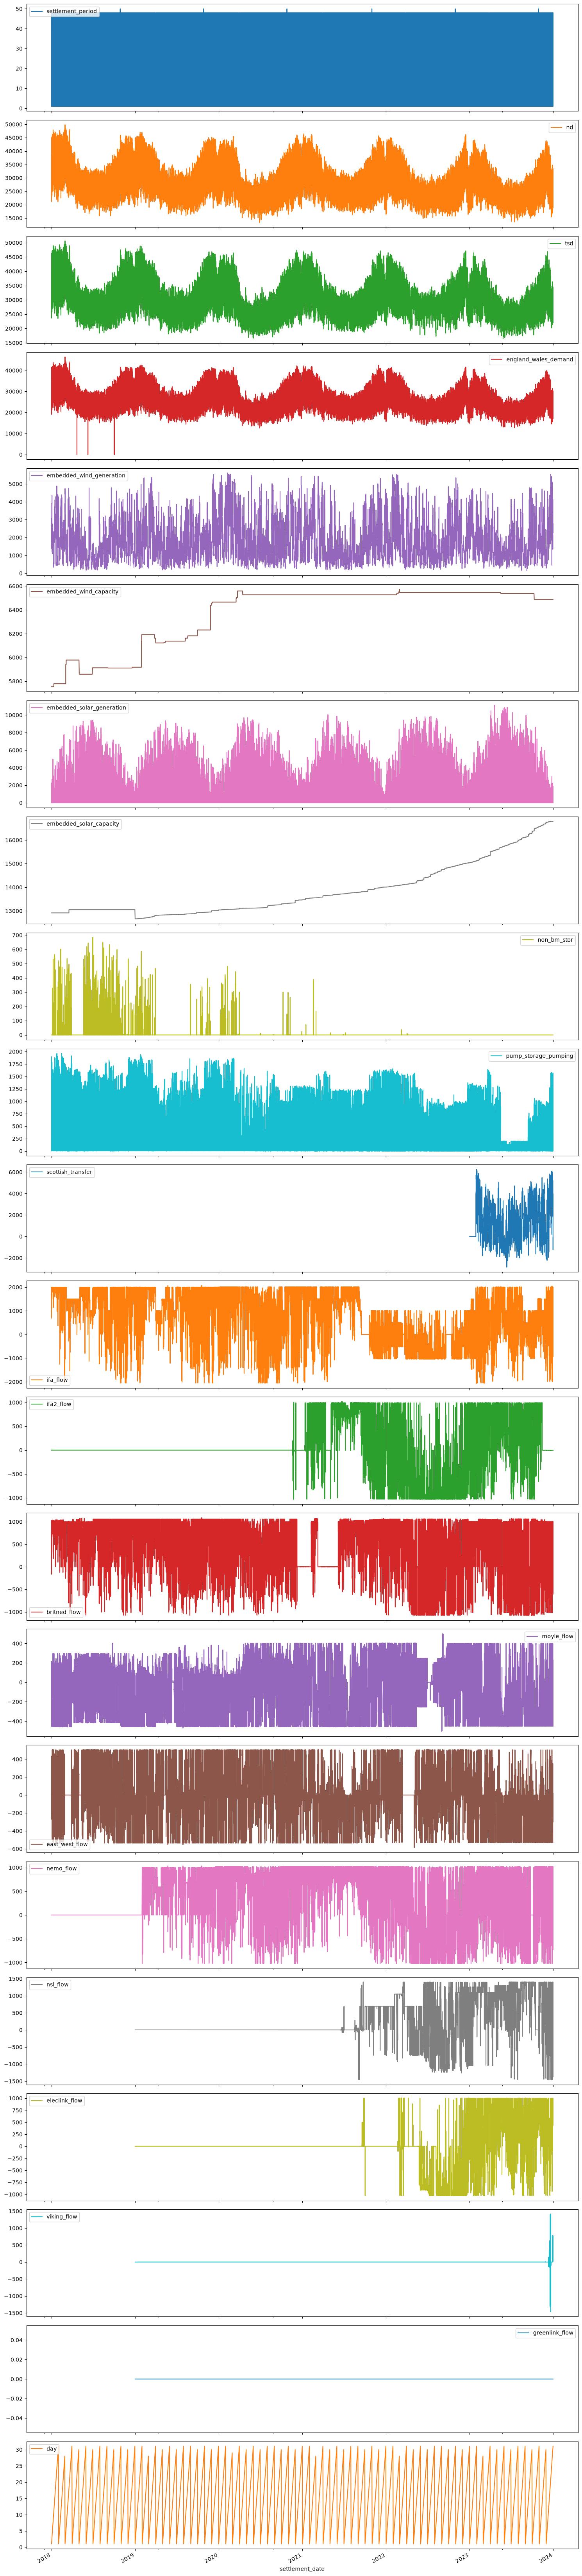

In [153]:
# plot each column over time 
df_merged.set_index('settlement_date', inplace=True)
num_cols = 1
num_rows = math.ceil(len(df_merged.columns) / num_cols)

# 3. Plot as a facet grid
df_merged.plot(
    subplots=True,
    layout=(num_rows, num_cols),
    figsize=(15, 3 * num_rows),
    sharex=True,  # Keeps timelines aligned
    sharey=False,  # Allows each column to keep its own scale
)

# 4. Polish and render
plt.tight_layout()
plt.show()

Notes from graph overall:
Capacity is the maximum the installations could produce. Generation is what they actually produced in that half-hour.

- National Demand behaves as expected - strong annual cycle (high in winter, lower in the summer); slower downward drift
    - anomaly detection model must account for the cycle otherwise the winter repeated annually will appear 'anomalous' during clustering 

- data errors - three drops in: england_wales_demand; recording errors; distinguish errors from anomalies
- embedded solar cpacity and generation similar cycle as ND, but counteractive (higher in summer lower in winter)
- capacity columns are estimations (not helpful or needed) 

In [155]:
df_merged.columns 

Index(['settlement_date', 'settlement_period', 'nd', 'tsd',
       'england_wales_demand', 'embedded_wind_generation',
       'embedded_wind_capacity', 'embedded_solar_generation',
       'embedded_solar_capacity', 'non_bm_stor', 'pump_storage_pumping',
       'scottish_transfer', 'ifa_flow', 'ifa2_flow', 'britned_flow',
       'moyle_flow', 'east_west_flow', 'nemo_flow', 'nsl_flow',
       'eleclink_flow', 'viking_flow', 'greenlink_flow', 'year', 'month',
       'day'],
      dtype='str')

In [156]:
df_merged.drop(columns = ['embedded_wind_capacity','embedded_solar_capacity'], inplace = True)

Change the time into datetime and time stamps

In [177]:
df_merged.settlement_date= pd.to_datetime(df_merged.settlement_date)
time_period = (df_merged.settlement_period - 1)*30

# turn minutes into time delta:
df_merged['timestamp'] = df_merged.settlement_date + pd.to_timedelta(time_period, unit = 'm')


In [179]:
df_merged = df_merged.set_index('timestamp')

Count time periods per day:

In [169]:
df_merged.day

timestamp
2018-01-01 00:00:00     1
2018-01-01 00:30:00     1
2018-01-01 01:00:00     1
2018-01-01 01:30:00     1
2018-01-01 02:00:00     1
                       ..
2023-12-31 21:30:00    31
2023-12-31 22:00:00    31
2023-12-31 22:30:00    31
2023-12-31 23:00:00    31
2023-12-31 23:30:00    31
Name: day, Length: 105168, dtype: int32

In [ ]:
results = df_merged.settlement_date.value_counts() # the number of time stamps per day
# they should be 48 as there are 1/2 hour increments
# any not 30 should be noted:
abnormal_rows = results[results != 48]
# 12 rows are reported 
abnormal_rows



settlement_date
2018-10-28    50
2019-10-27    50
2020-10-25    50
2021-10-31    50
2022-10-30    50
2023-10-29    50
2018-03-25    46
2019-03-31    46
2020-03-29    46
2021-03-28    46
2022-03-27    46
2023-03-26    46
Name: count, dtype: int64

- 46s are the last Sunday of March each year, when the clocks go forward and the day loses an hour.
- 50s are the last Sunday of October each year, when the clocks go back and the day gains an hour.

In [203]:
# 1. Ensure the data is sorted by date and settlement period
df_merged = df_merged.sort_values(by=['settlement_date', 'settlement_period']).reset_index(drop=True)
# 2. Generate a continuous 30-minute timestamp range starting at your baseline
gmt_timestamps = pd.date_range(
    start='2018-01-01 00:00:00', 
    periods=len(df_merged), 
    freq='30min', 
    tz='Etc/GMT'
)
df_merged['timestamp'] = gmt_timestamps


In [205]:
result = df_merged.settlement_date.value_counts()
result[result != 48]

settlement_date
2018-10-28    50
2019-10-27    50
2020-10-25    50
2021-10-31    50
2022-10-30    50
2023-10-29    50
2018-03-25    46
2019-03-31    46
2020-03-29    46
2021-03-28    46
2022-03-27    46
2023-03-26    46
Name: count, dtype: int64

Check for duplicates in the date and duplicate pair

In [209]:
df_merged[df_merged.duplicated(subset=["settlement_date", "settlement_period"])] # no duplicates basedon date or period


,settlement_date,settlement_period,nd,tsd,england_wales_demand,embedded_wind_generation,embedded_solar_generation,non_bm_stor,pump_storage_pumping,scottish_transfer,...,east_west_flow,nemo_flow,nsl_flow,eleclink_flow,viking_flow,greenlink_flow,year,month,day,timestamp


Missing values

In [214]:
df_merged.isna().sum()
# missing value
# scottish transfer - 87648
# nsl_flow - 17520
# eleclink_flow - 17520
# viking_flow - 17520
# greenlink_flow - 17520

settlement_date                  0
settlement_period                0
nd                               0
tsd                              0
england_wales_demand             0
embedded_wind_generation         0
embedded_solar_generation        0
non_bm_stor                      0
pump_storage_pumping             0
scottish_transfer            87648
ifa_flow                         0
ifa2_flow                        0
britned_flow                     0
moyle_flow                       0
east_west_flow                   0
nemo_flow                        0
nsl_flow                     17520
eleclink_flow                17520
viking_flow                  17520
greenlink_flow               17520
year                             0
month                            0
day                              0
timestamp                        0
dtype: int64

In [ ]:
df_merged[df_merged.england_wales_demand == 0]
# TSD is exactly ND + 500 on all three rows. That matches NESO’s note that TSD includes an estimated 500 MW of power-station usage in summer time. It’s another sign these rows are fine apart from the England & Wales column.
# the england_wakes_demand - did not record these dates despite the ND being present adn changin over the time increment
# They’re zeros, not NaN. That’s why a missing-value check wouldn’t catch them. Note them as “missing values recorded as 0”.

,settlement_date,settlement_period,nd,tsd,england_wales_demand,embedded_wind_generation,embedded_solar_generation,non_bm_stor,pump_storage_pumping,scottish_transfer,...,east_west_flow,nemo_flow,nsl_flow,eleclink_flow,viking_flow,greenlink_flow,year,month,day,timestamp
5341,2018-04-22,16,21830,22330,0,1436,1580,0,0,NaN,...,0,0,NaN,NaN,NaN,NaN,2018,4,22,2018-04-22 06:30:00+00:00
7664,2018-06-09,35,26870,27370,0,402,3420,0,0,NaN,...,0,0,NaN,NaN,NaN,NaN,2018,6,9,2018-06-09 16:00:00+00:00
13191,2018-10-02,42,34190,34690,0,2263,2,0,0,NaN,...,0,0,NaN,NaN,NaN,NaN,2018,10,2,2018-10-02 19:30:00+00:00


Get summary stats for ND, embedded solar generation and embedded wind generation: min, Q1, median, mean, Q3, max and IQR.

In [231]:
df_merged.describe(include = 'number', percentiles = [0.5, 0.75,0.99, 0.9999])

,settlement_period,nd,tsd,england_wales_demand,embedded_wind_generation,embedded_solar_generation,non_bm_stor,pump_storage_pumping,scottish_transfer,ifa_flow,...,moyle_flow,east_west_flow,nemo_flow,nsl_flow,eleclink_flow,viking_flow,greenlink_flow,year,month,day
count,105168.000000,105168.000000,105168.000000,105168.000000,105168.000000,105168.000000,105168.000000,105168.000000,17520.000000,105168.000000,...,105168.000000,105168.000000,105168.000000,87648.000000,87648.000000,87648.000000,87648.0,105168.000000,105168.00000,105168.000000
mean,24.500228,27963.008976,29594.285705,25561.344316,1813.965227,1397.683773,4.463211,221.554560,1355.594920,856.128043,...,-87.559182,0.536370,391.735461,290.496885,17.008021,1.132336,0.0,2020.499772,6.52476,15.726685
std,13.853860,6550.868025,6237.335170,5983.504108,1133.530640,2166.812211,36.024023,420.648911,1760.008033,1059.808317,...,273.441400,304.732528,557.306818,581.593902,429.693435,40.942019,0.0,1.707477,3.44843,8.798960
min,1.000000,13367.000000,16513.000000,0.000000,147.000000,0.000000,0.000000,0.000000,-2851.000000,-2056.000000,...,-505.000000,-585.000000,-1022.000000,-1455.000000,-1028.000000,-1465.000000,0.0,2018.000000,1.00000,1.000000
50%,24.500000,27202.000000,28823.000000,24814.000000,1532.000000,6.000000,0.000000,11.000000,1066.000000,1112.000000,...,-62.000000,0.000000,565.000000,0.000000,0.000000,0.000000,0.0,2020.000000,7.00000,16.000000
75%,36.250000,32167.000000,33428.000000,29414.000000,2501.000000,2263.000000,0.000000,140.250000,2616.000000,1805.000000,...,132.000000,185.000000,902.000000,693.000000,0.000000,0.000000,0.0,2022.000000,10.00000,23.000000
99%,48.000000,43840.330000,45146.000000,40019.330000,4940.330000,8353.660000,181.000000,1584.000000,5610.810000,2005.000000,...,401.000000,504.000000,1019.000000,1399.000000,999.000000,0.000000,0.0,2023.000000,12.00000,31.000000
99.99%,49.000000,47879.349700,49093.666000,43980.383100,5571.000000,10718.216100,607.933200,1916.483300,6224.729100,2034.483300,...,491.483300,504.000000,1020.000000,1400.000000,1001.000000,1408.000000,0.0,2023.000000,12.00000,31.000000
max,50.000000,49807.000000,50608.000000,46356.000000,5605.000000,11116.000000,684.000000,1963.000000,6238.000000,2065.000000,...,499.000000,504.000000,1033.000000,1401.000000,1002.000000,1408.000000,0.0,2023.000000,12.00000,31.000000


Plot a histogram of ND. Look for whether it has one peak or two.